# Die Face Classification with Harris Corners and SIFT + BoVW

The original notebook (`SIFT_Harris_corner.ipynb`) ran two classical pipelines on
the LFW face dataset from scikit-learn. This version keeps the same two ideas but
applies them to the **die-face dataset in this repository** instead.

**Dataset.** 179 already preprocessed images (224 × 224, single-channel 8-bit
grayscale PNG, background normalised to level 200):

- **set1 (bhuvan)**: 60 real phone photos, 10 per face
- **set2 (jai)**: 119 synthetic renders, 19-21 per face

Labels (face value 1-6) are read from each set's `metadata.csv`, so they always
match the preprocessing that produced the images.

**Pipelines compared.**

| # | Features | Classifier |
|---|----------|------------|
| 1 | Harris corner feature vector (response statistics + top corner coordinates + intensity histogram) | RBF SVM |
| 2 | SIFT descriptors → K-Means visual vocabulary → bag-of-visual-words histogram | RBF SVM |

A final section checks whether a model trained on one source set generalises to
the other, and a 5-fold cross-validation gives a more stable comparison.

> **Running locally:** open the notebook from inside this repository. The loader
> walks up from the current directory to find `set1(bhuvan)` and `set2(jai)`.
>
> **Running on Colab or Kaggle:** upload/import this notebook and run all cells.
> The first cell clones the public GitHub repository automatically when the data
> is not already present. On Kaggle, switch **Internet** on in the notebook
> settings first; on Colab it is available by default.
>
> Dependencies: `scikit-learn` in addition to OpenCV, NumPy, pandas and Matplotlib
> (`pip install scikit-learn`). Colab and Kaggle already include all of them.

## 0. Environment setup and dataset loading

This cell works locally and on hosted notebooks. It first looks for the dataset in
the current directory and its parents, then in the usual Colab/Kaggle working
directories. If nothing is found, it clones
`https://github.com/bhuvan11000/IP-mini-project-die-face-dataset` (shallow clone)
and changes into the repository, so the relative paths used below keep working.

In [1]:
import os
import subprocess
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

FACE_NAMES = [f"face {i}" for i in range(1, 7)]

REPO_URL = "https://github.com/bhuvan11000/IP-mini-project-die-face-dataset.git"
REPO_NAME = "IP-mini-project-die-face-dataset"


def has_dataset(path):
    return (path / "set1(bhuvan)" / "metadata.csv").exists() and (
        path / "set2(jai)" / "metadata.csv"
    ).exists()


def find_repo_root(start=None):
    '''Locate the dataset locally, or clone it when running on Colab/Kaggle.'''
    start = Path.cwd() if start is None else Path(start)

    # Local run: the notebook is somewhere inside the repository.
    for candidate in (start, *start.parents):
        if has_dataset(candidate):
            return candidate

    # Hosted run: the repository may already be cloned into a subdirectory.
    for base in (Path("/content"), Path("/kaggle/working")):
        candidate = base / REPO_NAME
        if has_dataset(candidate):
            return candidate

    # Kaggle: the repository may be attached as an input Dataset instead.
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for candidate in [kaggle_input, *kaggle_input.glob("*"), *kaggle_input.glob("*/*")]:
            if has_dataset(candidate):
                return candidate

    # Nothing found: clone the public GitHub repository.
    if Path("/content").exists():
        workdir = Path("/content")          # Google Colab
    elif Path("/kaggle/working").exists():
        workdir = Path("/kaggle/working")   # Kaggle
    else:
        workdir = start

    target = workdir / REPO_NAME
    print(f"Dataset not found locally. Cloning {REPO_URL} into {target} ...")
    result = subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(target)],
        capture_output=True,
        text=True,
    )
    if result.returncode != 0:
        raise RuntimeError(
            "git clone failed. On Kaggle, enable Internet in the notebook "
            f"settings and try again.\n\n{result.stderr.strip()}"
        )
    return target


REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)
print(f"Using dataset repository: {REPO_ROOT}")

DATASET_DIRS = {
    "set1": REPO_ROOT / "set1(bhuvan)",
    "set2": REPO_ROOT / "set2(jai)",
}

records, image_list = [], []
for set_name, set_dir in DATASET_DIRS.items():
    metadata = pd.read_csv(set_dir / "metadata.csv")
    for row in metadata.itertuples(index=False):
        image_path = set_dir / "processed" / f"{Path(row.filename).stem}.png"
        gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if gray is None:
            print(f"warning: could not read {image_path}")
            continue
        image_list.append(gray)
        records.append(
            {"file": image_path.name, "label": int(row.category), "set": set_name}
        )

images = np.stack(image_list)
meta = pd.DataFrame(records)
labels = meta["label"].to_numpy()
sets = meta["set"].to_numpy()

assert images.ndim == 3 and images.shape[1:] == (224, 224)
assert sorted(np.unique(labels)) == list(range(1, 7))

print(f"Loaded {len(images)} images, each {images.shape[1]}x{images.shape[2]} (uint8)")
print("Images per class and source:")
display(meta.groupby(["set", "label"]).size().unstack(fill_value=0))

Using dataset repository: /home/bhu1/sem5/ip/IP-mini-project-die-face-dataset
Loaded 179 images, each 224x224 (uint8)
Images per class and source:


label,1,2,3,4,5,6
set,,,,,,
set1,10,10,10,10,10,10
set2,20,19,20,20,21,19


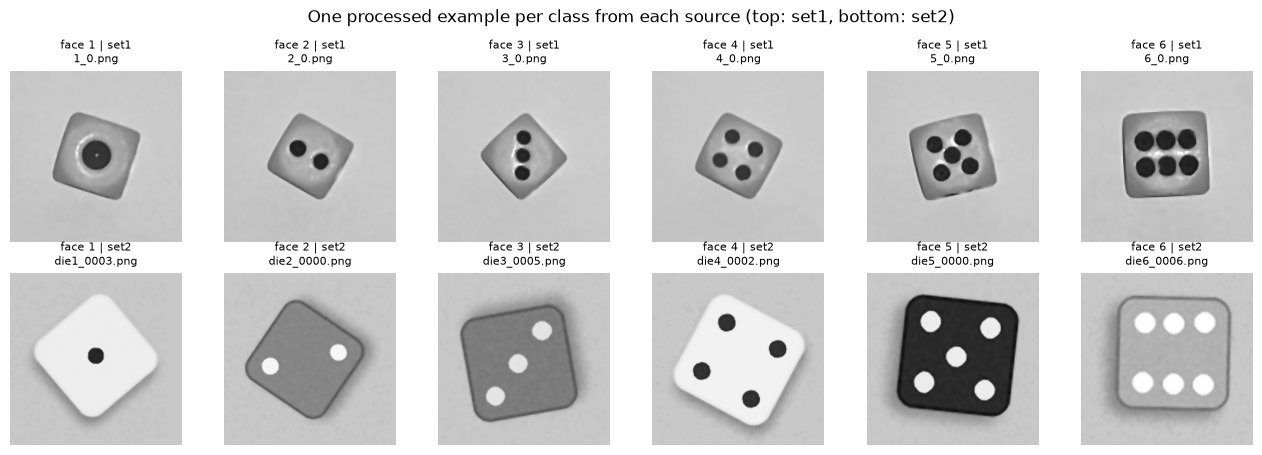

In [2]:
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for col, face in enumerate(range(1, 7)):
    for row, set_name in enumerate(DATASET_DIRS):
        idx = int(np.where((labels == face) & (sets == set_name))[0][0])
        ax = axes[row, col]
        ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
        ax.set_title(
            f"{FACE_NAMES[face - 1]} | {set_name}\n{meta.loc[idx, 'file']}", fontsize=8
        )
        ax.axis("off")

fig.suptitle(
    "One processed example per class from each source (top: set1, bottom: set2)",
    fontsize=12,
)
plt.tight_layout()
plt.show()

The preprocessing already did the hard part: the die is centred, the background is
uniform, and the pips are clearly visible. The remaining challenge is that the die
is rotated differently in every image, pips can be dark on a light die or light on
a dark die (set2), and set2 has synthetic shading and blur.

Two small helpers are used by both pipelines below: one prints accuracy per source
set, the other draws a confusion matrix.

In [3]:
def print_per_set_accuracy(y_true, y_pred, test_sets):
    for name in DATASET_DIRS:
        mask = test_sets == name
        print(
            f"  {name} only: {accuracy_score(y_true[mask], y_pred[mask]):.3f} "
            f"({mask.sum()} test images)"
        )


def show_confusion_matrix(y_true, y_pred, title):
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=range(1, 7),
        display_labels=FACE_NAMES,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 1. Harris corner features + SVM

This is the feature vector from the original notebook. For every image it
computes the Harris corner response, keeps corners above 1% of the strongest
response, and builds a 52-dimensional vector:

1. number of corners, mean / std / max response (4 values),
2. coordinates of the 20 strongest corners (40 values),
3. an 8-bin histogram of intensity at corner pixels (8 values).

The image is resized to 64 × 64 first. In the original notebook this was needed to
give LFW images a consistent size; here the inputs are already 224 × 224, but the
smaller scale is kept because it groups nearby pip edges into a few strong corner
responses instead of thousands of tiny ones.

In [4]:
def extract_harris_features(
    img_array, block_size=2, ksize=3, k=0.04, num_top_corners=20
):
    '''Detect Harris corners and return the fixed-length feature vector.'''
    # Convert float image matrix from sklearn to 8-bit grayscale (0-255)
    if img_array.max() <= 1.0:
        gray = (img_array * 255).astype(np.uint8)
    else:
        gray = img_array.astype(np.uint8)

    # Resize to standard size for consistent coordinate scaling
    gray = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)

    # 1. Compute Harris Corner Response Matrix
    harris_response = cv2.cornerHarris(np.float32(gray), block_size, ksize, k)

    # Thresholding to isolate strong corners
    thresh = 0.01 * harris_response.max()
    corner_mask = harris_response > thresh
    corner_responses = harris_response[corner_mask]

    # --- Feature 1: Global Response Statistics ---
    num_corners = np.sum(corner_mask)
    mean_response = np.mean(corner_responses) if num_corners > 0 else 0.0
    std_response = np.std(corner_responses) if num_corners > 0 else 0.0
    max_response = harris_response.max()

    # --- Feature 2: Top Corner Spatial Coordinates ---
    corner_y, corner_x = np.where(corner_mask)
    sorted_indices = np.argsort(harris_response[corner_y, corner_x])[::-1][
        :num_top_corners
    ]

    top_x = corner_x[sorted_indices]
    top_y = corner_y[sorted_indices]

    # Zero-pad coordinates if fewer than `num_top_corners` were detected
    if len(top_x) < num_top_corners:
        pad_len = num_top_corners - len(top_x)
        top_x = np.pad(top_x, (0, pad_len), mode="constant", constant_values=0)
        top_y = np.pad(top_y, (0, pad_len), mode="constant", constant_values=0)

    # --- Feature 3: Intensity Histogram around Corner Regions ---
    hist, _ = np.histogram(
        gray[corner_mask] if num_corners > 0 else [0],
        bins=8,
        range=(0, 256),
    )
    hist = hist / (np.sum(hist) + 1e-7)  # Normalize

    return np.hstack(
        [num_corners, mean_response, std_response, max_response, top_x, top_y, hist]
    )


X_harris = np.array([extract_harris_features(img) for img in images])
print(f"Harris feature matrix: {X_harris.shape[0]} samples x {X_harris.shape[1]} features")

Harris feature matrix: 179 samples x 52 features


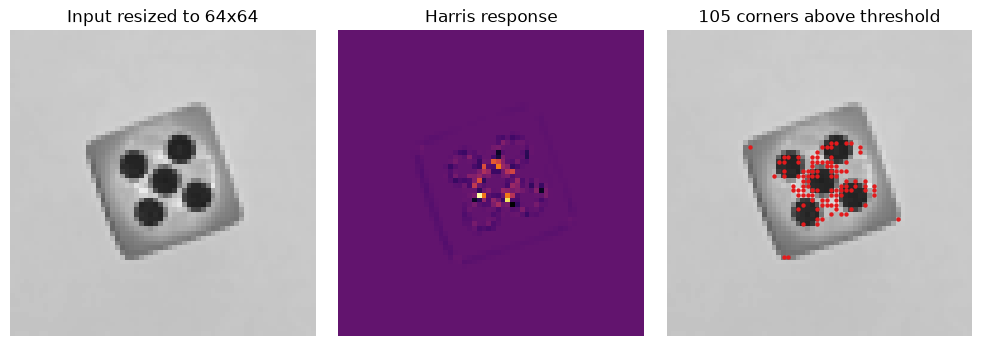

In [5]:
# Visualise what the Harris detector sees on one face-5 image
demo_idx = int(np.where(labels == 5)[0][2])
demo_gray = cv2.resize(images[demo_idx], (64, 64), interpolation=cv2.INTER_AREA)
demo_response = cv2.cornerHarris(np.float32(demo_gray), 2, 3, 0.04)
demo_response = demo_response / (np.abs(demo_response).max() + 1e-12)
demo_mask = demo_response > 0.01 * demo_response.max()

corner_y, corner_x = np.where(demo_mask)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
axes[0].imshow(demo_gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Input resized to 64x64")
axes[1].imshow(demo_response, cmap="inferno")
axes[1].set_title("Harris response")
axes[2].imshow(demo_gray, cmap="gray", vmin=0, vmax=255)
axes[2].scatter(corner_x, corner_y, s=10, c="#e31a1c", linewidths=0)
axes[2].set_title(f"{len(corner_x)} corners above threshold")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Train / test split

The split is stratified and shared with the SIFT pipeline, so both methods are
evaluated on exactly the same 45 test images.

HARRIS CORNERS + SVM - EVALUATION
Holdout accuracy: 48.89%
  set1 only: 0.818 (11 test images)
  set2 only: 0.382 (34 test images)



              precision    recall  f1-score   support

      face 1       0.54      0.88      0.67         8
      face 2       0.29      0.29      0.29         7
      face 3       0.50      0.57      0.53         7
      face 4       0.38      0.38      0.38         8
      face 5       0.57      0.50      0.53         8
      face 6       1.00      0.29      0.44         7

    accuracy                           0.49        45
   macro avg       0.55      0.48      0.47        45
weighted avg       0.54      0.49      0.48        45



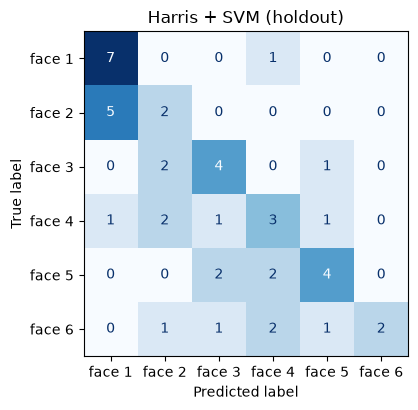

In [6]:
indices = np.arange(len(images))
idx_train, idx_test = train_test_split(
    indices, test_size=0.25, random_state=42, stratify=labels
)

harris_scaler = StandardScaler().fit(X_harris[idx_train])
harris_svm = SVC(kernel="rbf", C=10.0, gamma="scale")
harris_svm.fit(harris_scaler.transform(X_harris[idx_train]), labels[idx_train])

harris_pred = harris_svm.predict(harris_scaler.transform(X_harris[idx_test]))
harris_accuracy = accuracy_score(labels[idx_test], harris_pred)

print("=" * 42)
print("HARRIS CORNERS + SVM - EVALUATION")
print("=" * 42)
print(f"Holdout accuracy: {harris_accuracy * 100:.2f}%")
print_per_set_accuracy(labels[idx_test], harris_pred, sets[idx_test])
print()
print(
    classification_report(
        labels[idx_test], harris_pred, labels=range(1, 7), target_names=FACE_NAMES
    )
)
show_confusion_matrix(labels[idx_test], harris_pred, "Harris + SVM (holdout)")

The Harris descriptor reaches roughly 50%, which is well above the 16.7% chance
level for six classes, but far below SIFT. The reason is visible in the
visualisation: the strongest corners sit on pip edges **and** on the die border and
specular highlights. The vector records where the 20 strongest corners are, but not
the pip pattern itself, so a rotation of the die moves the coordinates and changes
the feature vector. The global response statistics add little class information.

## 2. SIFT descriptors + bag-of-visual-words + SVM

SIFT is a better fit for this task: it places keypoints on pip edges at different
scales and describes the local gradient pattern with a 128-dimensional,
rotation-normalised descriptor.

Descriptors have different counts per image, so they cannot go into an SVM
directly. The bag-of-visual-words approach fixes that:

1. Extract SIFT descriptors for every image.
2. Cluster the **training** descriptors with K-Means (`K = 200` visual words).
3. Encode each image as a histogram of visual-word assignments.
4. L2-normalise and apply square-root (power) normalisation, which is standard for
   BoVW and stops one very frequent visual word from dominating.
5. Train the RBF SVM on the histograms.

Fitting K-Means on training descriptors only avoids leaking test information into
the visual vocabulary.

SIFT keypoints per image: mean 33.6, min 2, max 83


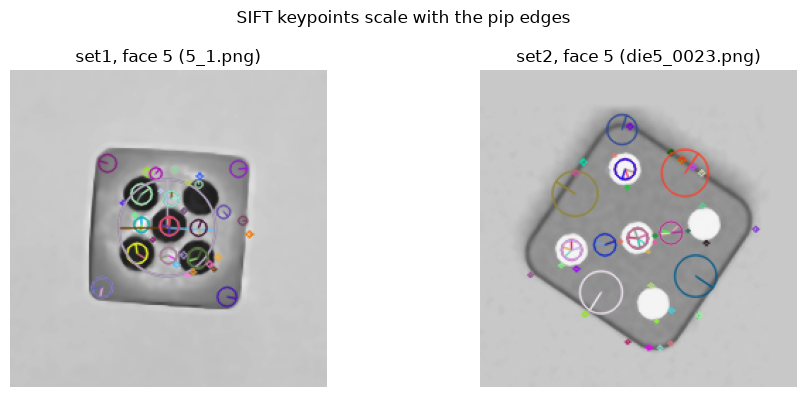

In [7]:
sift = cv2.SIFT_create()
keypoints_list, descriptors_list = [], []
for img in images:
    keypoints, descriptors = sift.detectAndCompute(img, None)
    keypoints_list.append(keypoints)
    descriptors_list.append(descriptors)

keypoint_counts = [0 if d is None else len(d) for d in descriptors_list]
print(f"SIFT keypoints per image: mean {np.mean(keypoint_counts):.1f}, "
      f"min {np.min(keypoint_counts)}, max {np.max(keypoint_counts)}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (set_name, face) in zip(axes, [("set1", 5), ("set2", 5)]):
    idx = int(np.where((sets == set_name) & (labels == face))[0][1])
    drawn = cv2.drawKeypoints(
        images[idx],
        keypoints_list[idx],
        None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
    )
    ax.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{set_name}, {FACE_NAMES[face - 1]} ({meta.loc[idx, 'file']})")
    ax.axis("off")
fig.suptitle("SIFT keypoints scale with the pip edges", fontsize=12)
plt.tight_layout()
plt.show()

In [8]:
def build_bovw_histograms(descriptors, kmeans_model, power_normalise=True):
    '''Convert variable-length SIFT descriptors to fixed-length histograms.'''
    vocab_size = kmeans_model.n_clusters
    histograms = []

    for desc in descriptors:
        if desc is None or len(desc) == 0:
            hist = np.zeros(vocab_size)
        else:
            visual_words = kmeans_model.predict(desc)
            hist, _ = np.histogram(visual_words, bins=np.arange(vocab_size + 1))

        # L2 normalisation
        norm = np.linalg.norm(hist)
        hist = hist / norm if norm > 0 else hist

        # Power normalisation: reduces the dominance of very frequent words
        if power_normalise:
            hist = np.sqrt(hist)

        histograms.append(hist)

    return np.array(histograms)


VOCAB_SIZE = 200
train_descriptors_stacked = np.vstack([descriptors_list[i] for i in idx_train])
print(
    f"Clustering {len(train_descriptors_stacked)} training descriptors "
    f"into {VOCAB_SIZE} visual words..."
)

kmeans = KMeans(n_clusters=VOCAB_SIZE, random_state=42, n_init=10)
kmeans.fit(train_descriptors_stacked)

X_train_sift = build_bovw_histograms(
    [descriptors_list[i] for i in idx_train], kmeans
)
X_test_sift = build_bovw_histograms(
    [descriptors_list[i] for i in idx_test], kmeans
)
print(f"BoVW feature matrix: {X_train_sift.shape[0]} train + {X_test_sift.shape[0]} test, "
      f"{X_train_sift.shape[1]} visual words")

Clustering 4496 training descriptors into 200 visual words...


BoVW feature matrix: 134 train + 45 test, 200 visual words


SIFT + BoVW + SVM - EVALUATION
Holdout accuracy: 91.11%
  set1 only: 1.000 (11 test images)
  set2 only: 0.882 (34 test images)

              precision    recall  f1-score   support

      face 1       1.00      1.00      1.00         8
      face 2       0.75      0.86      0.80         7
      face 3       1.00      1.00      1.00         7
      face 4       0.86      0.75      0.80         8
      face 5       1.00      0.88      0.93         8
      face 6       0.88      1.00      0.93         7

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



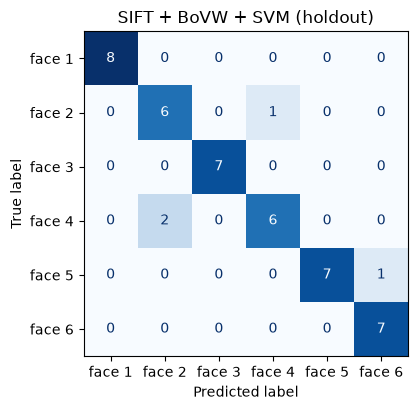

In [9]:
sift_scaler = StandardScaler().fit(X_train_sift)
sift_svm = SVC(kernel="rbf", C=10.0, gamma="scale")
sift_svm.fit(sift_scaler.transform(X_train_sift), labels[idx_train])

sift_pred = sift_svm.predict(sift_scaler.transform(X_test_sift))
sift_accuracy = accuracy_score(labels[idx_test], sift_pred)

print("=" * 42)
print("SIFT + BoVW + SVM - EVALUATION")
print("=" * 42)
print(f"Holdout accuracy: {sift_accuracy * 100:.2f}%")
print_per_set_accuracy(labels[idx_test], sift_pred, sets[idx_test])
print()
print(
    classification_report(
        labels[idx_test], sift_pred, labels=range(1, 7), target_names=FACE_NAMES
    )
)
show_confusion_matrix(labels[idx_test], sift_pred, "SIFT + BoVW + SVM (holdout)")

SIFT reaches about 91% on the same test images, close to a 6× reduction in error
compared with Harris. It recognises the pip edges independent of the die rotation,
and the visual-word histogram captures the pip arrangement. Most remaining mistakes
are between faces with similar-looking pip patterns (for example 4 vs 5) and on
blurred or partially cropped synthetic dice.

## 3. Does the model generalise across the two sources?

Set1 (phone photos) and set2 (synthetic renders) share the same preprocessing, but
they look very different. A combined random split lets the classifier see both
domains in training. To measure the real domain gap, train on **one entire set** and
test on the other. The SIFT pipeline is used because it was the stronger one.

In [10]:
def evaluate_cross_set(train_set, test_set):
    train_idx = np.where(sets == train_set)[0]
    test_idx = np.where(sets == test_set)[0]

    train_desc = [descriptors_list[i] for i in train_idx]
    test_desc = [descriptors_list[i] for i in test_idx]

    vocab = KMeans(n_clusters=VOCAB_SIZE, random_state=42, n_init=10)
    vocab.fit(np.vstack(train_desc))

    X_cross_train = build_bovw_histograms(train_desc, vocab)
    X_cross_test = build_bovw_histograms(test_desc, vocab)

    scaler = StandardScaler().fit(X_cross_train)
    svm = SVC(kernel="rbf", C=10.0, gamma="scale")
    svm.fit(scaler.transform(X_cross_train), labels[train_idx])

    pred = svm.predict(scaler.transform(X_cross_test))
    acc = accuracy_score(labels[test_idx], pred)

    print(
        f"Train on {train_set} ({len(train_idx)} images) -> "
        f"test on {test_set} ({len(test_idx)} images): {acc * 100:.2f}%"
    )
    return acc


cross_set2_to_set1 = evaluate_cross_set("set2", "set1")
cross_set1_to_set2 = evaluate_cross_set("set1", "set2")
print(f"\nChance level: {100 / 6:.1f}%")

Train on set2 (119 images) -> test on set1 (60 images): 25.00%


Train on set1 (60 images) -> test on set2 (119 images): 25.21%

Chance level: 16.7%


Cross-set accuracy collapses to roughly 20-30%. The pipeline has learned
source-specific appearance (shading, contrast, blur, die texture), not a
source-independent notion of "four pips". This is the classic domain-shift problem:
a model evaluated on a random split of pooled data looks much better than one that
has to transfer to a new acquisition setup. For a real deployment, you would mix
both sources in training, normalise appearance more aggressively, or add
augmentation that mimics the other domain.

## 4. Stable comparison with 5-fold cross-validation

A single 75/25 split can be lucky or unlucky, especially with only 179 images.
This repeats both pipelines 5 times with different stratified folds. The SIFT
vocabulary is re-fitted inside each fold, so no test descriptors leak into the
codebook.

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
harris_cv_scores, sift_cv_scores = [], []

for fold_train, fold_test in skf.split(images, labels):
    # Harris
    scaler = StandardScaler().fit(X_harris[fold_train])
    svm = SVC(kernel="rbf", C=10.0, gamma="scale")
    svm.fit(scaler.transform(X_harris[fold_train]), labels[fold_train])
    harris_cv_scores.append(
        accuracy_score(labels[fold_test], svm.predict(scaler.transform(X_harris[fold_test])))
    )

    # SIFT + BoVW
    vocab = KMeans(n_clusters=VOCAB_SIZE, random_state=42, n_init=10)
    vocab.fit(np.vstack([descriptors_list[i] for i in fold_train]))
    X_fold_train = build_bovw_histograms(
        [descriptors_list[i] for i in fold_train], vocab
    )
    X_fold_test = build_bovw_histograms(
        [descriptors_list[i] for i in fold_test], vocab
    )
    scaler = StandardScaler().fit(X_fold_train)
    svm = SVC(kernel="rbf", C=10.0, gamma="scale")
    svm.fit(scaler.transform(X_fold_train), labels[fold_train])
    sift_cv_scores.append(
        accuracy_score(labels[fold_test], svm.predict(scaler.transform(X_fold_test)))
    )

print(f"{'Method':<22}{'Holdout':>10}{'5-fold CV':>18}")
print("-" * 50)
print(f"{'Harris + SVM':<22}{harris_accuracy:>9.3f}"
      f"{np.mean(harris_cv_scores):>13.3f} +/- {np.std(harris_cv_scores):.3f}")
print(f"{'SIFT + BoVW + SVM':<22}{sift_accuracy:>9.3f}"
      f"{np.mean(sift_cv_scores):>13.3f} +/- {np.std(sift_cv_scores):.3f}")

Method                   Holdout         5-fold CV
--------------------------------------------------
Harris + SVM              0.489        0.481 +/- 0.066
SIFT + BoVW + SVM         0.911        0.888 +/- 0.032


## 5. Conclusions

- **Harris corners are a weak descriptor for die faces.** The 52-D vector encodes
  response magnitudes and absolute corner positions. It reaches about 48-50%
  accuracy, barely above what a few dominant corner statistics can separate, and it
  is sensitive to die rotation.
- **SIFT + BoVW works well.** About 91% on the single holdout and 89% under 5-fold
  CV. SIFT's rotation-normalised local gradients on the pip edges plus a
  visual-word histogram capture the pip arrangement that defines the face value.
- **Domain shift is real.** Training on synthetic set2 and testing on real set1
  (or the reverse) drops to 20-30%. Pooled random-split accuracy therefore
  overstates how well the model would work on a new camera or renderer.
- **Classical features have a ceiling here.** The next step that would likely add
  most value is not a better SVM kernel but a task-specific detector: segment the
  die, find the pips as blobs/circles, and count them (or feed the count plus
  layout to a classifier). That uses the structure of a die directly. A CNN
  trained with set1+set2 and augmentation would be the learned alternative.

**Files used:** `set1(bhuvan)/metadata.csv`, `set1(bhuvan)/processed/*.png`,
`set2(jai)/metadata.csv`, `set2(jai)/processed/*.png`.